# Does an answer carry the unit of its question? The unit gate on the committed case documents

**Question:** When a method's answer is right in its own unit and wrong in the unit of the question (a probability written in percent, a capital in thousands, a constant of another observable), which rule of the unit gate sees it, how far must the answer be off before the gate blocks, and which errors does the gate let through?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 75 minutes

## Objectives

By the end of this notebook you can:

- say why a gate that asks whether the pipeline ran never sees an answer in the wrong unit, and show on the engine's own tests which mistakes a test already refuses and which it reports as a bad model;
- write the widened range of the four kinds of target (a series, a 0/1 outcome, one known truth and a bound) as an equation, and compute it by hand on a committed document;
- read the specification `data-pipeline/config/unit_pairs.json`: the entry of a case, the path of a prediction and of its target, the kind, the unit, the zero scale and the domain;
- run `pipeline.stages.unit_gate` on committed documents of four cases and read the verdict of every pair, blocking and advisory;
- plant a percent, a factor of 1,000 and two sign flips in a copy of a document, and read the class of violation the gate names for each;
- measure where the gate starts to block a multiplicative error and set the measured threshold against the one the rule states;
- name, with code, what the gate lets through (an error inside the widened range, an error downward, an exact zero, a bound that is only a domain, a missing prediction) and declare a pair for a file of your own.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 pandas==3.0.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The unit gate is one file of the product's pipeline, `data-pipeline/pipeline/stages/unit_gate.py`, written with the standard library alone so that the shipped check can load it by path. The pipeline is plain scripts and not a package, so the next cell puts `data-pipeline/` on the import path and imports the stage from there: one function for the shipped check, the tests and this notebook (the bake joins them in the next release), never a copy. The engine `riskvalidation` is imported only for the tests of step 2. The notebook reads committed files and never writes one. The cell prints the version of every package and the constants the stage defines.

In [1]:
# Put the pipeline on the import path, import the unit gate and print the versions
import fnmatch
import importlib.metadata as md
import json
import sys
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.validation import calibration as cal, discrimination as disc

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.stages import unit_gate as gate


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


for name in ("riskvalidation", "numpy", "pandas", "matplotlib"):
    print(name, md.version(name))
print("constants of the rule:", "RANGE_SLACK =", gate.RANGE_SLACK, "| FLAT_REL =", gate.FLAT_REL)
print("kinds of target:", gate.KINDS)
print("entries of a case:", gate.ENTRY_KINDS)

riskvalidation 1.1.0
numpy 2.4.6
pandas 3.0.6
matplotlib 3.11.2
constants of the rule: RANGE_SLACK = 1.0 | FLAT_REL = 1e-06
kinds of target: ('series', 'binary', 'scalar', 'bound')
entries of a case: ('pairs', 'bake_only', 'withheld', 'not_applicable')


## Data

The notebook follows one rule over documents of five cases, all of them committed.

- **The specification:** `data-pipeline/config/unit_pairs.json`, written for this product. It declares, per built case, which prediction is scored against which target and in which unit.
- **C01, retail PD (`data/derived/C01/german-twin.json`):** the German Credit data, Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data, licence class `mirror-allowed` (CC BY 4.0). Truth status `real-outcomes`: 1,000 real applicants.
- **C09, exposure at default (`data/derived/C09/level-0.json`):** generated by the product's own generator; truth status `synthetic-known-truth`, no third-party data.
- **C16, reverse liquidity stress (`data/derived/C16/fast-run.json`):** a calibrated run on the sources FDIC BankFind, the Federal Reserve H.8 release, the Federal Reserve review of Silicon Valley Bank (2023-04-28) and the Treasury par curve, all licence class `mirror-allowed`; truth status `synthetic-calibrated`.
- **C17, operational-risk capital (`data/derived/C17/xi-0-8.json`) and C05, low-default portfolios (`data/derived/C05/ldp-sim-1.json`):** generated by the product's own generators, truth status `synthetic-known-truth`.
- **Committed documents read** (paths from the repository root): the specification and the five documents above. Nothing else is read.

## Method

Every gate of the product asks whether the pipeline ran: the schemas, contract 1 on the inputs, contract 2 on the documents, determinism under a seed, the expected ranges of each case. The unit gate asks the one question those gates never ask, whether a method's answer is in the unit of the question it is scored against. It judges a prediction against its target and nothing more: a method may be badly wrong and be reported as badly wrong, and it may not answer a different question (a PD written in percent, a capital in thousands) while being scored as if it answered this one. It is never an accuracy gate. The notebook walks the rule in seven steps, on the committed documents, and then turns to where it stops seeing.

### Step 1: the failure the gate exists for

The rule behind the gate was written, as its own record tells it, after a defect in another research product: a method written for a recovery fraction on the unit interval kept its constants when the matrix of cases grew to observables in megawatts, and a control predicted exactly 1.00 against a target of 433 to 484 megawatts. Every gate the product had said the pipeline ran, and it had. The next cell builds three such answers in memory, a PD of 22 for a PD of 0.22, a capital of 163,483,000 euros where the case works in thousands, and a constant of 1.00 against a target of 433 to 484, and asks the stage for its verdict on each. A pair is a small dictionary (`file`, `prediction`, `target`, `kind`, `unit`, and for a bounded observable its `domain` and the reason), and `check_document` judges a document against the pairs of a case.

In [2]:
# Three answers that are right in their own unit and wrong in the unit of their question, judged by the gate
def toy_pair(kind, unit, **extra):
    return {
        "id": "toy",
        "file": "toy.json",
        "prediction": "prediction",
        "target": "target",
        "kind": kind,
        "unit": unit,
        **extra,
    }


def toy_verdict(pair, prediction, target):
    document = {"prediction": prediction, "target": target}
    return gate.check_document("T01", "toy.json", document, {"T01": {"pairs": [pair]}})


reason = "A probability lies in [0, 1] by definition."
percent = toy_pair("series", "probability", domain=[0, 1], domain_reason=reason)
cases = [
    ("a PD written in percent", percent, [22.0], [0.21, 0.24, 0.27]),
    ("a capital in thousands of euros", toy_pair("scalar", "EUR"), [163483.0 * 1000], [163483.0]),
    ("a constant reused in another observable", toy_pair("series", "MW"), [1.0, 1.0, 1.0], [433.0, 450.0, 484.0]),
]
rows = []
for label, pair, prediction, target in cases:
    result = toy_verdict(pair, prediction, target)
    classes = ", ".join(sorted({v["class"] for v in result.violations}))
    rows.append({"the answer": label, "blocks": bool(result.violations), "classes": classes})
pd.DataFrame(rows)

,the answer,blocks,classes
0,a PD written in percent,True,"prediction_outside_domain, prediction_outside_..."
1,a capital in thousands of euros,True,prediction_outside_observable
2,a constant reused in another observable,True,prediction_outside_observable


All three are blocked, and for different reasons. The PD of 22 is refused twice, by the domain of a probability (`prediction_outside_domain`: ONE prediction outside [0, 1] is enough) and by the widened range of its target (`prediction_outside_observable`: every nonzero prediction lies outside it). The capital of 163,483,000 against a truth of 163,483 and the constant 1.00 against 433 to 484 are refused by the widened range alone, because neither observable declares a domain. The table does not say how far off an answer has to be before it is blocked, nor what the gate does with an answer that is wrong in the other direction; both are the subject of the sections below.

### Step 2: what the engine's tests make of the same mistake

The engine `riskvalidation` already refuses some wrong-unit inputs, and it is worth seeing which, because the gate and the engine overlap on probabilities and part ways everywhere else. The next four cells take the scorecard PD of the 50 German applicants that the committed twin holds, in three versions: as baked, written in percent (multiplied by 100) and divided by 10. The first calls the AUC. The AUC reads only the order of the scores, so a change of scale cannot move it.

In [3]:
# The engine's AUC on the scorecard PD of 50 German applicants: as baked, written in percent and divided by 10
twin = read_json("data/derived/C01/german-twin.json")
sample = twin["outputs"]["sample"]
defaults = np.array(sample["targets"])
pd_sample = np.array(sample["scorecard_pd"])
policy = default_policy()
versions = (("as baked", 1.0), ("written in percent (x 100)", 100.0), ("divided by 10", 0.1))
rows = []
for label, factor in versions:
    result = disc.disc_auc(pd_sample * factor, defaults, policy=policy)
    rows.append(
        {"PD": label, "AUC": round(result.metric, 4), "largest PD": round(float((pd_sample * factor).max()), 3)}
    )
pd.DataFrame(rows)

,PD,AUC,largest PD
0,as baked,0.7566,0.846
1,written in percent (x 100),0.7566,84.601
2,divided by 10,0.7566,0.085


The AUC is 0.7566 in all three versions, although the largest PD reads 0.846, 84.601 and 0.085. This is the pattern the unit rule is about: a number that is right in its own unit and silent about the unit. A discrimination test cannot tell a probability from a score on any other scale, and a gate that only watched the AUC would pass the percent. The table shows that one engine test is blind to scale. It does not show what the tests that do read the probability make of the same inputs, which the next cell asks with the Brier score and the expected calibration error.

In [4]:
# The engine's Brier score and expected calibration error on the same three versions: a refusal is printed, not
# hidden
rows = []
for label, factor in versions:
    scaled = pd_sample * factor
    try:
        brier = round(cal.pd_brier(defaults, scaled, policy=policy).metric, 4)
    except ValueError as refusal:
        brier = str(refusal)
    try:
        ece = round(cal.pd_ece(defaults, scaled, policy=policy).metric, 4)
    except ValueError as refusal:
        ece = str(refusal)
    rows.append({"PD": label, "Brier": brier, "ECE": ece})
pd.DataFrame(rows)

,PD,Brier,ECE
0,as baked,0.1544,0.0919
1,written in percent (x 100),pd must lie strictly between 0 and 1,pd must lie strictly between 0 and 1
2,divided by 10,0.2224,0.2197


The calibration tests refuse the percent: `pd must lie strictly between 0 and 1`, for the Brier score and the error alike. The version divided by 10 is accepted and returns a Brier score of 0.2224 against 0.1544, and a calibration error of 0.2197 against 0.0919. The engine has no way to know that the second is a unit slip and not a worse model, and it reports it as what it can see, a model whose probabilities do not match the outcomes. The next two cells ask the two calibration tests that return a light, Hosmer-Lemeshow and then Spiegelhalter.

In [5]:
# The engine's Hosmer-Lemeshow test on the three versions: the p-value and the light the policy gives
rows = []
for label, factor in versions:
    try:
        result = cal.pd_hosmer_lemeshow(defaults, pd_sample * factor, policy=policy)
        verdict = f"p = {result.p_value:.3f}, {result.light.value}"
    except ValueError as refusal:
        verdict = str(refusal)
    rows.append({"PD": label, "Hosmer-Lemeshow": verdict})
pd.DataFrame(rows)

,PD,Hosmer-Lemeshow
0,as baked,"p = 0.928, green"
1,written in percent (x 100),pd must lie strictly between 0 and 1
2,divided by 10,"p = 0.000, red"


Hosmer-Lemeshow gives a p-value of 0.928 and the light green on the PD as baked, refuses the percent with the same message and turns red on the PD divided by 10. The Spiegelhalter test reads the same three versions in the next cell.

In [6]:
# The engine's Spiegelhalter test on the three versions: the p-value and the light the policy gives
rows = []
for label, factor in versions:
    try:
        result = cal.pd_spiegelhalter(defaults, pd_sample * factor, policy=policy)
        verdict = f"p = {result.p_value:.3f}, {result.light.value}"
    except ValueError as refusal:
        verdict = str(refusal)
    rows.append({"PD": label, "Spiegelhalter": verdict})
pd.DataFrame(rows)

,PD,Spiegelhalter
0,as baked,"p = 0.576, green"
1,written in percent (x 100),pd must lie strictly between 0 and 1
2,divided by 10,"p = 0.000, red"


Hosmer-Lemeshow and Spiegelhalter give a p-value of 0.928 and 0.576 and the light green on the PD as baked, and both refuse the percent with the same message and turn red, with a p-value that prints as 0.000, on the PD divided by 10. So the engine does see the divided PD, as a calibration failure, and a reader who looks at a red light looks for a bad model. That is what the engine is for. The unit gate sits one level up, on the documents the product writes, and says that a document whose predictions are in the wrong unit is not a model result at all. The last engine cell probes the edge of the engine's domain.

In [7]:
# Where the engine's domain starts and ends, probed with the Brier score: a PD of exactly 0 or 1 and of 0.999 and
# 0.001
rows = []
edge = toy_pair("bound", "probability", domain=[0, 1], reason="A probability lies in [0, 1] by definition.")
for value in (0.0, 0.001, 0.5, 0.999, 1.0, 1.0000001, 1.5):
    try:
        brier = round(cal.pd_brier(defaults, np.full(len(defaults), value), policy=policy).metric, 4)
    except ValueError as refusal:
        brier = str(refusal)
    blocks = len(toy_verdict(edge, [value] * 3, [0.2, 0.3, 0.4]).violations)
    rows.append({"PD given to every applicant": value, "engine, Brier score": brier, "gate, violations": blocks})
pd.DataFrame(rows)

,PD given to every applicant,"engine, Brier score","gate, violations"
0,0.000,pd must lie strictly between 0 and 1,0
1,0.001,0.2395,0
2,0.500,0.25,0
3,0.999,0.7585,0
4,1.000,pd must lie strictly between 0 and 1,0
5,1.000,pd must lie strictly between 0 and 1,1
6,1.500,pd must lie strictly between 0 and 1,1


The engine accepts a constant PD of 0.001, 0.5 and 0.999 and refuses exactly 0, exactly 1 and 1.5: its domain is the open interval. The gate's domain for a probability is the closed interval [0, 1], and the last column of the table, a bound pair judged by the gate, passes 0 and 1 and blocks 1.0000001 and 1.5. The two guards agree that 22 is not a probability and disagree on the edge, and neither judges accuracy. The engine's tests guard only the probabilities they are called on. The gate guards the observables its judged pairs name: amounts in dollars and euros, shares of a deposit base, losses per quarter, capitals. The next three steps give the rule its equations.

### Step 3: the four kinds of target, and the rule as equations

The stage defines two constants and four kinds. `RANGE_SLACK` $r = 1.0$ is the rule's own: one full range on each side. `FLAT_REL` $\varepsilon = 10^{-6}$ is the fraction of a scale below which a series counts as flat (a comment of the stage names it as taken from the rule's reference implementation). Everything else, the zero scale $z$ and the domain $D$, is declared per pair in the specification. For a pair the stage first widens the target. With the target values $T$, their minimum $t_{\min}$ and maximum $t_{\max}$ and the span $s = t_{\max} - t_{\min}$, the widened range $W$ of each kind is

$$W_{\mathrm{series}} = [\,t_{\min} - r\,s,\; t_{\max} + r\,s\,]\ \ (s > 0), \qquad W_{\mathrm{binary}} = [\,0 - r,\; 1 + r\,] = [-1,\, 2], \qquad W_{\mathrm{scalar}} = [\,t - r\,|t|,\; t + r\,|t|\,]$$

with $[t_{\min} - z, t_{\max} + z]$ when a series has span 0 and $[-z, z]$ when a scalar truth $t$ is 0, which is why a pair that can meet those cases declares its zero scale $z$ and a pair that meets one without it is an error. A series is an observed vector. A binary target is a 0/1 outcome reported as bin or cohort rates, whose label domain $[0, 1]$ is widened by its own span. A scalar is one known truth, and it must resolve to exactly one value. A bound is a prediction that is not an estimate of its target (a confidence upper bound after few defaults): it is compared with no target and must only be finite and inside its declared domain.

With $P$ the predictions, $P^{*} = \{p \in P : p \neq 0\}$ the nonzero ones and $D = [d_{\mathrm{lo}}, d_{\mathrm{hi}}]$ the declared domain (open at an end when it is `null`), the gate blocks a pair when

$$\underbrace{\exists\, p \in P \mid p \notin \mathbb{R}}_{\text{non finite}} \quad \lor \quad \underbrace{\exists\, p \in P \mid p \notin D}_{\text{outside domain}} \quad \lor \quad \underbrace{P^{*} \neq \emptyset \ \land\ \forall\, p \in P^{*} \mid p \notin W}_{\text{outside observable}}$$

A prediction partly inside the widened range passes: that is what keeps the gate about units. An exact zero is the same number in every unit and carries no evidence of scale, so it is left out of $P^{*}$. A null prediction is a missing value and is counted as an advisory, and a constant prediction $p_{\max} - p_{\min} \le \varepsilon\,\max(|p_{\min}|, |p_{\max}|, 10^{-12})$ over a target whose span exceeds the same fraction of its scale is another advisory, because a flat answer is legitimate when the driver does not move. Of the three classes that block, the first two are about a single value and the third about all of them. A bound is reported under the third class: a value outside its domain is `prediction_outside_observable`. The next step reads how the specification names the pairs these equations apply to.

### Step 4: the specification of every case

`data-pipeline/config/unit_pairs.json` is the data the stage reads: it holds no code. A case has one entry, of one of four kinds: `pairs` (a prediction and its target are in the committed documents and are judged there), `withheld` (the target may not be published, so from the next release the bake will judge these pairs in memory; today no verdict is recorded for them), `bake_only` (the predictions never reach a document beside their target, so a hook in the bake would judge them) and `not_applicable` (nothing is predicted and scored against a target, said in one sentence). The stage validates the whole specification with `validate_spec` before it judges anything, so a malformed pair stops the run, naming the case and the pair. The next cell reads the specification, validates it and counts what it declares.

In [8]:
# Read the specification, validate it with the gate's own validator and count what it declares
spec = read_json("data-pipeline/config/unit_pairs.json")
gate.validate_spec(spec)
entry_kind = {case: next(k for k in gate.ENTRY_KINDS if k in entry) for case, entry in spec.items()}
pairs = [dict(p, case=case) for case, entry in spec.items() for p in entry.get("pairs", []) + entry.get("withheld", [])]
frame = pd.DataFrame(pairs)
bounds = frame["kind"] == "bound"
print("cases in the specification:", len(spec))
print("entries by kind:", pd.Series(entry_kind).value_counts().to_dict())
print("cases that also withhold a target:", sum("withheld" in e for e in spec.values()))
print("pairs:", len(frame), "| by kind of target:", frame["kind"].value_counts().to_dict())
print(
    "domains: on the three estimating kinds, on bounds:",
    int(frame.loc[~bounds, "domain"].notna().sum()),
    int(frame.loc[bounds, "domain"].notna().sum()),
)
print("pairs that declare a zero scale:", int(frame["zero_scale"].notna().sum()))

cases in the specification: 21
entries by kind: {'pairs': 18, 'bake_only': 2, 'not_applicable': 1}
cases that also withhold a target: 1
pairs: 53 | by kind of target: {'series': 19, 'bound': 14, 'scalar': 11, 'binary': 9}
domains: on the three estimating kinds, on bounds: 21 14
pairs that declare a zero scale: 9


The specification covers 21 cases: 18 with pairs, two `bake_only` and one `not_applicable`, and one of the 18, C11, also withholds the target of four of its windows. It declares 53 pairs, 19 of the kind series, 14 bound, 11 scalar and 9 binary. A domain is declared by 21 pairs of the three estimating kinds, which is the count of the feature's design, and by all 14 bounds, for which a domain is required; and 9 pairs declare a zero scale. The counts say how much of the product the rule touches. They do not say how each pair is written, which the next cell shows for one case.

In [9]:
# The entry of one case, C09, field by field: where its prediction and its target live and which kind judges them
columns = ["id", "file", "prediction", "target", "kind", "unit", "group_by", "zero_scale", "domain"]
pd.DataFrame(spec["C09"]["pairs"]).reindex(columns=columns).set_index("id").T

id,c09-ead-backtest,c09-ccf-by-design
file,level-*.json,level-*.json
prediction,outputs.ead_backtest.rows[].predicted_ead,outputs.ccf_by_design.rows[].estimate.value
target,outputs.ead_backtest.rows[].realised_ead,outputs.ccf_by_design.rows[].truth.value
kind,series,scalar
unit,USD,CCF (fraction of the undrawn limit)
group_by,NaN,outputs.ccf_by_design.rows[]
zero_scale,NaN,1.0
domain,"[0, None]",NaN


The entry of C09 has two pairs. The first scores the predicted exposure at default of every row of the backtest against the realised one, as a series in US dollars, with the domain $[0, \infty)$ (the `null` that prints as `None` is an open end): an exposure at default is non-negative by definition. The second scores the credit-conversion factor of each design against its known truth, as a scalar, and `group_by` makes every row of `ccf_by_design.rows[]` its own pair, with a zero scale of 1.0 because a truth can be exactly 0 by construction. The `file` is a glob over the case's documents, so `level-*.json` reaches the six levels. A path ends in `[]` to walk a list and may carry `<m>` to walk the keys of a map and bind the method a violation names. The next cell lists the cases that carry no pairs and why.

In [10]:
# How many pairs and domains each case declares, and why the cases without pairs have none
per_case = frame.groupby("case").agg(pairs=("id", "count"), domains=("domain", lambda s: int(s.notna().sum())))
others = {case: spec[case][kind] for case, kind in entry_kind.items() if kind in ("bake_only", "not_applicable")}
print("cases with pairs:", len(per_case), "| pairs:", int(per_case["pairs"].sum()))
for case, why in others.items():
    print(case, entry_kind[case], ":", (why["reason"] if isinstance(why, dict) else why)[:100])
per_case.T

cases with pairs: 18 | pairs: 53
C13 bake_only : The desk VaR forecast per replication exists only inside the bake (measure.py runs the engine once p
C20 bake_only : The PD arrays and the labels of the ladder exist only inside the bake (fits.py); the artifacts ship 
C21 not_applicable : The four estimators of the approval-rate disparity coefficient are not predictions scored against a 


case,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,C11,C12,C14,C15,C16,C17,C18,C22
pairs,3,1,3,14,6,2,1,2,2,3,4,2,1,3,2,1,1,2
domains,3,1,3,13,6,2,0,0,1,1,0,2,0,0,2,0,0,1


Eighteen cases carry 53 pairs between them, from one pair in several cases to 14 in C04. C13 and C20 are `bake_only`: their forecasts exist only inside the bake, and the specification names the hook that will judge them. C21 is `not_applicable`: the estimators of a disparity coefficient are not predictions scored against a target. The table gives the number of pairs and of domains per case. It does not say whether the paths of a pair resolve on every document its glob reaches, which the shipped check and the tests settle for the whole tree. Step 5 takes one document and applies the rule by hand.

### Step 5: the rule by hand on one document, then by the gate

The function below writes the widened range of a kind exactly as the equations of step 3 do (it uses the stage's own `RANGE_SLACK`). The notebook applies it to the C09 backtest: it reads the 56 rows of the document, widens the realised exposures, counts the nonzero predictions that fall inside and then asks the gate. The two have to agree.

In [11]:
# The widened range of a target by the rule of its kind, written as the equations above and used by hand below
def widened_range(kind, target, zero_scale=None):
    if kind == "binary":
        return [0.0 - gate.RANGE_SLACK, 1.0 + gate.RANGE_SLACK]
    if kind == "scalar":
        scale = abs(target[0]) if target[0] != 0 else zero_scale
        return [target[0] - scale, target[0] + scale]
    span = max(target) - min(target)
    scale = gate.RANGE_SLACK * span if span > 0 else zero_scale
    return [min(target) - scale, max(target) + scale]


def ead_rows(document):
    return document["outputs"]["ead_backtest"]["rows"]


document = read_json("data/derived/C09/level-0.json")
backtest = ead_rows(document)
predicted = [row["predicted_ead"] for row in backtest]
realised = [row["realised_ead"] for row in backtest]
low, high = widened_range("series", realised)
nonzero = [p for p in predicted if p != 0.0]
print("backtest rows:", len(backtest), "| methods pooled:", len({r["model_id"] for r in backtest}))
print(
    "realised EAD, USD:",
    f"[{min(realised):,.0f}, {max(realised):,.0f}]",
    "| span:",
    f"{max(realised) - min(realised):,.0f}",
)
print("widened range, USD:", f"[{low:,.0f}, {high:,.0f}]")
print("predicted EAD, USD:", f"[{min(predicted):,.0f}, {max(predicted):,.0f}]")
print("nonzero predictions inside the range:", sum(low <= p <= high for p in nonzero), "/", len(nonzero))

backtest rows: 56 | methods pooled: 8
realised EAD, USD: [3,757,760, 214,843,283] | span: 211,085,523
widened range, USD: [-207,327,763, 425,928,805]
predicted EAD, USD: [4,715,178, 213,039,179]
nonzero predictions inside the range: 56 / 56


The 56 rows come from eight methods pooled into one pair, because the pair's prediction path has no `<m>`. The realised exposure runs from 3,757,760 to 214,843,283 US dollars, a span of 211,085,523, so the widened range is $[-207{,}327{,}763,\ 425{,}928{,}805]$: the span is added once on each side. The predictions run from 4,715,178 to 213,039,179, and all 56 are inside the range. The lower end of the range is negative, which matters in the sections that follow. The next cell asks the gate for the same document.

In [12]:
# The same document judged by the gate: the verdict has to agree with the hand computation
result = gate.check_document("C09", "level-0.json", document, spec)
print(
    "pair checks:", result.pairs_checked, "| blocking:", len(result.violations), "| advisories:", len(result.advisories)
)
print("entry of the case:", result.entry)

pair checks: 2 | blocking: 0 | advisories: 0
entry of the case: pairs


The gate reports two pair checks on this document (the two pairs of the entry that match `level-0.json`), no blocking violation and no advisory, as the hand computation says. The entry kind it returns is `pairs`. To read the other kinds the same way, the next cells collect, for four pairs of four cases, where the prediction and the target sit in their document.

The next cell defines a function that reads the values by hand from the places the specification names, for C01 the `pd` and the observed rate `dr` of every reliability bin of every rung, for C16 the first denominator of the scoring, for C17 the capital quantiles of every method against the one truth of the 99.9 percent annual loss, and for C09 the backtest. The cell prints how many C09 predictions it reads.

In [13]:
# Where the prediction and the target of each pair sit in its document, read by hand (the gate walks the same paths)
def values_at(document, pair_id):
    out = document["outputs"]
    if pair_id == "c01-reliability-bins":
        rows = [r for rung in out["rungs"].values() for r in rung["reliability"] if r["pd"] is not None]
        return [r["pd"] for r in rows], [r["dr"] for r in rows]
    if pair_id == "c16-denominators":
        first = out["scoring"]["denominators"][0]
        return [first["modelled_share"]], [first["realised_share"]]
    if pair_id == "c17-capital-quantile":
        cells = [m.get("capital_eur", {}) for c in out["cells"] for m in c["capital"].values()]
        return [v for cell in cells for v in cell.values()], [out["truth"]["annual_loss_quantile"]["value_eur"]]
    return [r["predicted_ead"] for r in ead_rows(document)], [r["realised_ead"] for r in ead_rows(document)]


read = values_at(read_json("data/derived/C09/level-0.json"), "c09-ead-backtest")
print("predictions and targets read from C09:", [len(values) for values in read])

predictions and targets read from C09: [56, 56]


The function returns the predictions and the targets of a pair as two lists. The next cell widens each target by the rule of its kind and counts the nonzero predictions that fall inside.

In [14]:
# One real pair of each of the four kinds of target: the widened range by the rule and the predictions that fall
# inside it
shown = [
    ("C01", "german-twin.json", "c01-reliability-bins"),
    ("C09", "level-0.json", "c09-ead-backtest"),
    ("C16", "fast-run.json", "c16-denominators"),
    ("C17", "xi-0-8.json", "c17-capital-quantile"),
]
rows = []
for case, rel, pair_id in shown:
    pair = next(p for p in spec[case]["pairs"] if p["id"] == pair_id)
    prediction, target = values_at(read_json(f"data/derived/{case}/{rel}"), pair_id)
    wide = widened_range(pair["kind"], target, pair.get("zero_scale"))
    inside = sum(wide[0] <= p <= wide[1] for p in prediction if p != 0.0)
    rows.append(
        {
            "pair": pair_id,
            "kind": pair["kind"],
            "widened range": f"[{wide[0]:.4g}, {wide[1]:.4g}]",
            "n": len(prediction),
            "inside": inside,
        }
    )
pd.DataFrame(rows).set_index("pair")

,kind,widened range,n,inside
pair,,,,
c01-reliability-bins,binary,"[-1, 2]",80,80
c09-ead-backtest,series,"[-2.073e+08, 4.259e+08]",56,56
c16-denominators,scalar,"[0, 1.7]",1,1
c17-capital-quantile,scalar,"[0, 3.27e+08]",80,68


The four kinds give four different ranges. The binary pair of C01 has the fixed range $[-1, 2]$ and all 80 reliability PDs are inside. The series of C09 has the range of the previous cell and 56 of 56 inside. The scalar of C16, one denominator whose realised share is 0.85, has the range $[0, 1.7]$: $t \pm |t|$ with $t = 0.85$. The scalar of C17, whose truth is 163,483,000 euros, has $[0, 3.27\cdot 10^{8}]$, and 68 of its 80 capital quantiles are inside, the other 12 being estimates above twice the truth. Twelve predictions outside the range do not block, because the others are inside: the gate asks whether the answer is in the unit of the question, and an estimate that is three times too large is still in euros. The table cannot show the gate's reaction to a real error. The next step plants one.

### Step 6: the gate on committed documents, and where it runs

The cell below runs the gate on one committed document of each of four cases and prints a row per pair that matches the document: the kind, the number of blocking violations and the advisory classes. It judges with the same function the shipped check `scripts/check_units.py` calls on every committed document under `data/derived/`, in the continuous-integration workflow and before a Pages deployment (`.github/workflows/ci.yml`, `.github/workflows/deploy-pages.yml`, and both smoke scripts).

In [15]:
# Run the gate itself on committed documents of four cases and print the verdict of every pair they carry
shipped = [("C01", "german-twin.json"), ("C09", "level-0.json"), ("C16", "fast-run.json"), ("C17", "xi-0-8.json")]
rows = []
for case, rel in shipped:
    result = gate.check_document(case, rel, read_json(f"data/derived/{case}/{rel}"), spec)
    for pair in spec[case]["pairs"]:
        if not fnmatch.fnmatchcase(rel, pair["file"]):
            continue
        blocking = [v for v in result.violations if v["pair"] == pair["id"]]
        advisory = sorted({v["class"] for v in result.advisories if v["pair"] == pair["id"]})
        rows.append(
            {
                "case": case,
                "document": rel,
                "pair": pair["id"],
                "kind": pair["kind"],
                "blocking": len(blocking),
                "advisories": ", ".join(advisory) or "-",
            }
        )
verdicts = pd.DataFrame(rows)
print("pairs judged:", len(verdicts), "| blocking in all:", int(verdicts["blocking"].sum()))
verdicts

pairs judged: 8 | blocking in all: 0


,case,document,pair,kind,blocking,advisories
0,C01,german-twin.json,c01-reliability-bins,binary,0,degenerate_constant_prediction
1,C01,german-twin.json,c01-grade-bins,binary,0,missing_prediction
2,C01,german-twin.json,c01-scorecard-sample,binary,0,-
3,C09,level-0.json,c09-ead-backtest,series,0,-
4,C09,level-0.json,c09-ccf-by-design,scalar,0,-
5,C16,fast-run.json,c16-denominators,scalar,0,-
6,C16,fast-run.json,c16-table-a1,series,0,missing_prediction
7,C17,xi-0-8.json,c17-capital-quantile,scalar,0,-


Eight pairs are judged on four documents and none blocks. The kinds are mixed: three binary pairs of probabilities, a series of amounts, a scalar CCF, a scalar of a share, a series of shares and a scalar of euros. Three advisories appear, and none blocks. The first PD pair of C01 carries `degenerate_constant_prediction`, because one rung (the constant control) predicts the same PD for every bin while the observed rates vary. The grade-bin pair of C01 and the table of C16 carry `missing_prediction`: some rungs have no value in some bins and the document says so with a null. A reader who sees an advisory has a fact to read, not a defect to fix.

At this release the gate judges the committed documents, in continuous integration and before a deployment. The check inside the bake, which would refuse to write a document whose predictions fail the gate, is planned for the next release: the stage's docstring and the feature's design describe the bake as a caller, and `stages/export.py` does not call the gate yet. A document baked before that release is therefore protected by the shipped check only, run on the committed files.

### Step 7: plant errors in memory and read the verdict

A gate is trusted when it is seen to fail. The next cell defines one function, `scale`, that edits a copy of a document in memory by multiplying its predictions by a factor $k$ (nothing is written). The four plants are the PD of every reliability bin of C01 multiplied by 100 (a percent), the predicted exposure of C09 multiplied by 1,000, the same exposure with its sign flipped ($k = -1$) and the capital quantiles of C17 with their sign flipped. The cell after it judges a clean copy and a planted copy of each and prints the classes.

In [16]:
# One function for every plant: it multiplies the predictions of a copy of a document by a factor k, in memory only
def scale(document, case, k):
    out = document["outputs"]
    if case == "C01":
        for rung in out["rungs"].values():
            for row in rung["reliability"]:
                row["pd"] = None if row["pd"] is None else row["pd"] * k
    elif case == "C09":
        for row in ead_rows(document):
            row["predicted_ead"] *= k
    else:
        for cell in out["cells"]:
            for method in cell["capital"].values():
                method["capital_eur"] = {q: v * k for q, v in method.get("capital_eur", {}).items()}
    return document


doc09 = read_json("data/derived/C09/level-0.json")
print(
    "first predicted exposure, as baked and after k = 1000 and k = -1:",
    [round(ead_rows(scale(deepcopy(doc09), "C09", k))[0]["predicted_ead"]) for k in (1, 1000, -1)],
)

first predicted exposure, as baked and after k = 1000 and k = -1: [33097977, 33097976512, -33097977]


The function edits values only and returns the document it is given, so a caller passes a deep copy; the last line shows the first predicted exposure of C09 as baked, with a factor of 1,000 and with a factor of $-1$. The next cell judges the clean document and its planted copy for each plant.

In [17]:
# Judge a clean copy and a planted copy of each document and read the class the gate names for the planted one
plants = [
    ("PD in percent", "C01", "german-twin.json", 100),
    ("exposure x 1,000", "C09", "level-0.json", 1000),
    ("exposure, sign flipped", "C09", "level-0.json", -1),
    ("capital, sign flipped", "C17", "xi-0-8.json", -1),
]
rows = []
for label, case, rel, k in plants:
    path = f"data/derived/{case}/{rel}"
    clean = gate.check_document(case, rel, read_json(path), spec)
    planted = gate.check_document(case, rel, scale(deepcopy(read_json(path)), case, k), spec)
    classes = ", ".join(sorted({v["class"] for v in planted.violations}))
    rows.append(
        {
            "planted error": label,
            "clean blocks": len(clean.violations),
            "planted blocks": len(planted.violations),
            "classes": classes,
        }
    )
pd.DataFrame(rows)

,planted error,clean blocks,planted blocks,classes
0,PD in percent,0,13,"prediction_outside_domain, prediction_outside_..."
1,"exposure x 1,000",0,1,prediction_outside_observable
2,"exposure, sign flipped",0,1,prediction_outside_domain
3,"capital, sign flipped",0,4,prediction_outside_observable


The clean copies block nothing and every planted copy is blocked. The PD in percent is blocked 13 times: by the domain class on all eight methods and by the observable class on five of them. The exposure multiplied by 1,000 is blocked once (the pair pools the eight methods) by the observable class, because every nonzero prediction now lies beyond $4.26\cdot 10^{8}$. The sign flip of an exposure is caught by the domain class, because an exposure is non-negative by definition, although the widened range of that pair reaches below zero and would let a negative number through: this is why a declared domain is a separate rule and not an extra widening. The capital with its sign flipped has no domain (a capital is the quantity the case estimates, not a quantity bounded by definition) and is caught by the observable class in four methods. The table does not show why the gate says what it says. The next cell compares the range it reports with the hand computation.

In [18]:
# The widened range the gate reports for the planted exposure equals the one computed by hand: the equation is the
# rule
planted = scale(deepcopy(read_json("data/derived/C09/level-0.json")), "C09", 1000)
verdict = gate.check_document("C09", "level-0.json", planted, spec).violations[0]
print("range reported by the gate:", [round(x) for x in verdict["target_range"]])
print("range computed by hand:", [round(x) for x in (low, high)])
print(
    "predictions the gate saw:",
    verdict["n_predictions"],
    "| their range:",
    [f"{x:.3g}" for x in verdict["prediction_range"]],
)
print(verdict["detail"])

range reported by the gate: [-207327763, 425928805]
range computed by hand: [-207327763, 425928805]
predictions the gate saw: 56 | their range: ['4.72e+09', '2.13e+11']
c09-ead-backtest: predicts [4.71518e+09, 2.13039e+11] against a widened target range [-2.07328e+08, 4.25929e+08] USD: every nonzero prediction lies outside the observable, so this method is answering a different question


The range the gate reports, $[-207{,}327{,}763,\ 425{,}928{,}805]$, is the range computed by hand in step 5 to the unit, and the message names what the gate saw: 56 predictions between $4.72\cdot 10^{9}$ and $2.13\cdot 10^{11}$, every one outside. The equation of step 3 is therefore the rule and not a description of it. The message is the text a developer meets in a failing CI step, and it names the pair, the range of the prediction, the widened range and the unit. It does not say what went wrong in the method, which is the reader's work. The figure draws the before and after of two of the plants.

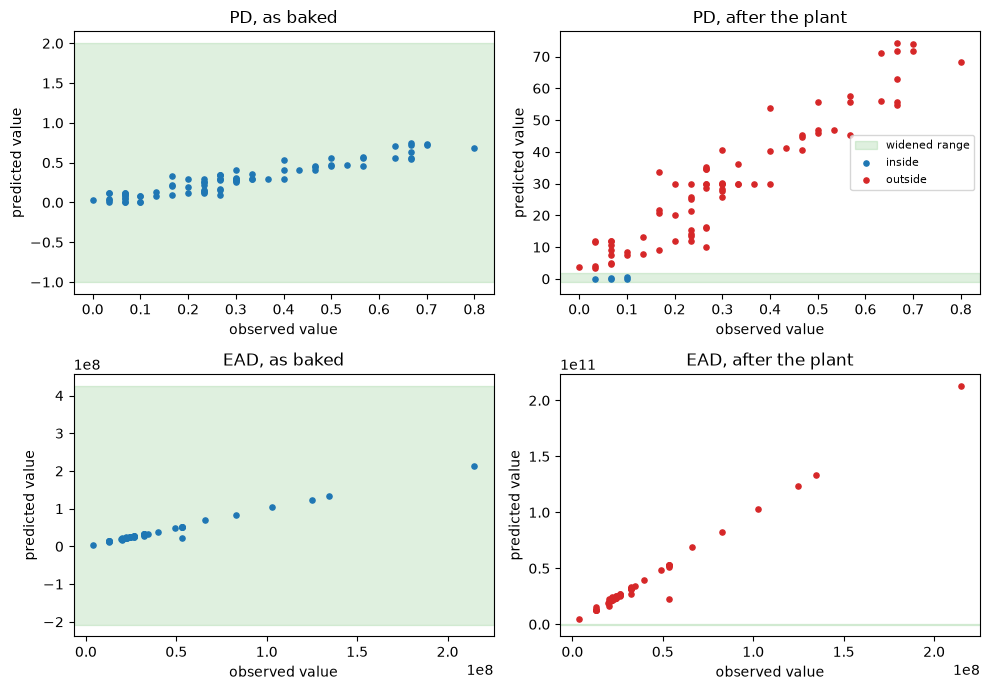

In [19]:
# Draw the prediction against its target before and after two plants, with the gate's widened range as a band
pairs = [
    ("C01", "german-twin.json", "c01-reliability-bins", 100, [-1, 2], "PD"),
    ("C09", "level-0.json", "c09-ead-backtest", 1000, None, "EAD"),
]
titles = ("as baked", "after the plant")
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, (case, rel, pair_id, k, band, label) in enumerate(pairs):
    clean = read_json(f"data/derived/{case}/{rel}")
    band = band or widened_range("series", values_at(clean, pair_id)[1])
    for col, document in enumerate((clean, scale(deepcopy(clean), case, k))):
        predicted, observed = (np.array(v) for v in values_at(document, pair_id))
        inside = (predicted >= band[0]) & (predicted <= band[1])
        ax = axes[row, col]
        ax.axhspan(band[0], band[1], color="tab:green", alpha=0.15, label="widened range")
        ax.scatter(observed[inside], predicted[inside], s=14, color="tab:blue", label="inside")
        ax.scatter(observed[~inside], predicted[~inside], s=14, color="tab:red", label="outside")
        ax.set_title(f"{label}, {titles[col]}")
        ax.set_xlabel("observed value")
        ax.set_ylabel("predicted value")
axes[0, 1].legend(loc="center right", fontsize=8)
fig.tight_layout()
plt.show()

The top row is the PD of C01 against the observed default rate of each bin, as baked on the left and in percent on the right, with the widened range $[-1, 2]$ as the green band. Before the plant every point is blue and inside, with the predicted PD between 0 and 0.74. After it 75 of the 80 points are red and they reach 74, far above the band (five stay blue inside it: zeros and values of at most 0.02 before the factor), while the observed rates have not moved. The bottom row is the exposure of C09 against the realised exposure on linear axes: before, the points follow the diagonal inside the band; after, the multiplied predictions fill the plot to $2\cdot 10^{11}$ and the band becomes a thin strip at the bottom. The figure shows what the gate sees, a cloud that has left the band. It does not show a defect that stays inside the band, which the next figure and the section on where the gate breaks take up.

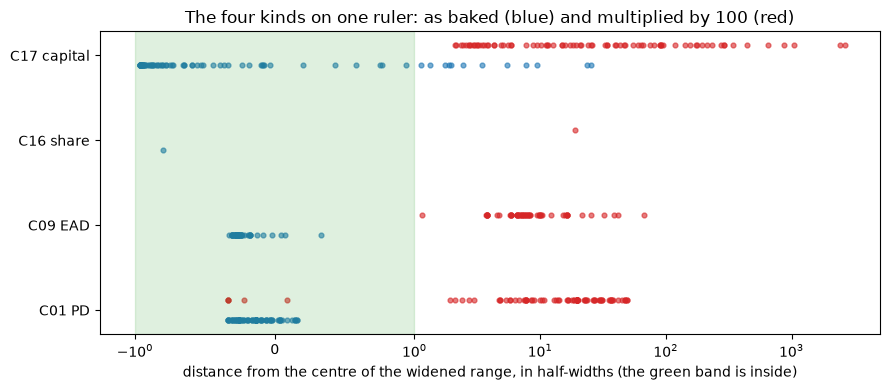

In [20]:
# Put the four kinds on one ruler: each prediction as a distance from the centre of its widened range, in half-
# widths
pairs_shown = [
    ("C01", "german-twin.json", "c01-reliability-bins", "C01 PD"),
    ("C09", "level-0.json", "c09-ead-backtest", "C09 EAD"),
    ("C16", "fast-run.json", "c16-denominators", "C16 share"),
    ("C17", "xi-0-8.json", "c17-capital-quantile", "C17 capital"),
]
fig, ax = plt.subplots(figsize=(9, 4))
for row, (case, rel, pair_id, label) in enumerate(pairs_shown):
    pair = next(p for p in spec[case]["pairs"] if p["id"] == pair_id)
    prediction, target = values_at(read_json(f"data/derived/{case}/{rel}"), pair_id)
    wide = widened_range(pair["kind"], target, pair.get("zero_scale"))
    centre, half = (wide[0] + wide[1]) / 2, (wide[1] - wide[0]) / 2
    for factor, colour in ((1, "tab:blue"), (100, "tab:red")):
        z = [(p * factor - centre) / half for p in prediction if p != 0.0]
        ax.scatter(z, [row + (0.12 if factor == 100 else -0.12)] * len(z), s=12, color=colour, alpha=0.6)
ax.axvspan(-1, 1, color="tab:green", alpha=0.15)
ax.set_xscale("symlog", linthresh=1)
ax.set_yticks(range(len(pairs_shown)))
ax.set_yticklabels([p[3] for p in pairs_shown])
ax.set_xlabel("distance from the centre of the widened range, in half-widths (the green band is inside)")
ax.set_title("The four kinds on one ruler: as baked (blue) and multiplied by 100 (red)")
fig.tight_layout()
plt.show()

The figure puts the four kinds on one ruler: each nonzero prediction as its distance from the centre of its widened range, measured in half-widths, so that the green band is the inside and every kind can be compared. The blue dots, the documents as baked, sit inside the band or beyond it only by the estimates above twice the truth (C17), and the red dots, the same predictions multiplied by 100, leave it: 75 of the 80 PDs of C01, all 56 exposures of C09 (the nearest at 1.14 half-widths), the share of C16 (at 19.1) and all 80 capitals of C17 (from 2.1 to 2,641 half-widths). The symmetric logarithmic axis makes the point of the next section visible too: multiplying by 100 leaves the band by a wide margin, and multiplying by 1.5 would not. The figure shows one factor. It does not show the factor at which each pair starts to block, which the sweep measures.

### Where the method changes or breaks

The gate asks whether every nonzero prediction lies outside a range that is as wide as the target's own span on each side. That generosity is deliberate, and it fixes what the gate can see. This section sweeps a multiplicative error on three documents to measure where it starts to block, sets the measured thresholds against the ones the rule states, and then shows with code five things the gate lets through. The sweep applies the function `scale` with factors from 0.001 to 10,000 on 71 logarithmic steps to the German twin (eight methods judged), the C09 backtest (one pooled pair) and C17 (four methods), and keeps at each factor the share of judged methods the gate blocks.

In [21]:
# Sweep the factor from 0.001 to 10,000 and keep, at each factor, the share of judged methods the gate blocks
subjects = {"C01": "german-twin.json", "C09": "level-0.json", "C17": "xi-0-8.json"}
judged = {"C01": 8, "C09": 1, "C17": 4}
factors = np.logspace(-3, 4, 71)


def blocked_methods(case, k):
    planted = scale(deepcopy(read_json(f"data/derived/{case}/{subjects[case]}")), case, float(k))
    return {v["method"] for v in gate.check_document(case, subjects[case], planted, spec).violations}


share = {case: [len(blocked_methods(case, k)) / judged[case] for k in factors] for case in subjects}
below = {case: max(s for s, k in zip(share[case], factors) if k < 1) for case in subjects}
full = {case: round(float(next(k for s, k in zip(share[case], factors) if s == 1.0)), 2) for case in subjects}
print("largest share blocked at a factor below 1:", below)
print("smallest factor on the grid that blocks every judged method:", full)

largest share blocked at a factor below 1: {'C01': 0.0, 'C09': 0.0, 'C17': 0.0}
smallest factor on the grid that blocks every judged method: {'C01': 3.98, 'C09': 100.0, 'C17': 79.43}


Below a factor of 1 the largest share blocked is 0.0 on all three documents: dividing every prediction by anything between 1 and 1,000 is never blocked (the next cells say why). Above 1 the three documents differ. Every method of the German twin is blocked from a factor of 3.98 on the grid, every method of C17 from 79.43 and the pooled exposure of C09 from 100. The grid is coarse, so the next cell measures the threshold of five methods exactly and sets it beside the threshold the rule implies. For a positive prediction multiplied by $k$ the range rule blocks when the smallest nonzero prediction leaves the range at its upper end, and the domain rule when the largest leaves the domain:

$$k^{*}_{\mathrm{range}} = \frac{w_{\mathrm{hi}}}{p_{\min}}, \qquad k^{*}_{\mathrm{domain}} = \frac{d_{\mathrm{hi}}}{p_{\max}}$$

where $w_{\mathrm{hi}}$ is the upper end of $W$ and $p_{\min}$ the smallest nonzero prediction of the method, and $d_{\mathrm{hi}}$ the upper end of the domain and $p_{\max}$ the largest prediction. The bisection below runs the gate itself on a planted copy at each step.

The cell defines the measurement: `first_block` bisects the factor between 1 and $10^{6}$ with 40 halvings of the logarithm, calling the gate at each, and `stated_threshold` evaluates the equation above from the document. It then runs both for five methods.

In [22]:
# The factor at which one method starts to be blocked: measured by bisection on the gate and stated by the rule as
# an equation
def first_block(case, method, low=1.0, high=1e6):
    for _ in range(40):
        middle = (low * high) ** 0.5
        low, high = (low, middle) if method in blocked_methods(case, middle) else (middle, high)
    return high


def stated_threshold(case, method):
    document = read_json(f"data/derived/{case}/{subjects[case]}")
    if case == "C01":
        rows = document["outputs"]["rungs"][method]["reliability"]
        return 1.0 / max(r["pd"] for r in rows if r["pd"] is not None)
    if case == "C09":
        predicted, target = values_at(document, "c09-ead-backtest")
        return widened_range("series", target)[1] / min(predicted)
    target = [document["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]]
    own = [v for c in document["outputs"]["cells"] for v in c["capital"][method].get("capital_eur", {}).values()]
    return widened_range("scalar", target)[1] / min(own)


probes = [("C01", "P1-scorecard"), ("C01", "P0-constant"), ("C09", None), ("C17", "sla"), ("C17", "lda_lognormal")]
rows = []
for case, method in probes:
    stated, measured = stated_threshold(case, method), first_block(case, method)
    rows.append(
        {
            "case": case,
            "method": method or "all pooled",
            "stated": round(stated, 3),
            "measured": round(measured, 3),
            "relative gap": f"{abs(measured / stated - 1):.1e}",
        }
    )
pd.DataFrame(rows)

,case,method,stated,measured,relative gap
0,C01,P1-scorecard,1.350,1.350,6.8e-12
1,C01,P0-constant,3.333,3.333,1.1e-11
2,C09,all pooled,90.331,90.331,5.9e-12
3,C17,sla,14.760,14.760,7.8e-12
4,C17,lda_lognormal,64.497,64.497,1.2e-11


The measured and the stated thresholds agree to a relative gap of about $10^{-11}$, which is the tolerance of the bisection: the scorecard of the German twin is blocked from a factor of 1.350 and the constant control from 3.333, both by the domain rule (the largest PD of the first is 0.74 and of the second 0.30); the pooled exposure of C09 from 90.331; the SLA capital of C17 from 14.760 and its lognormal LDA from 64.497, by the range rule. The thresholds differ a lot between methods and cases, from 1.35 to 64.5, and it is worth reading why. The domain rule is the strict one: a PD only has to cross 1. The range rule needs every prediction to cross the upper end, so the method with the smallest prediction, relative to the target's range, decides. The next figure draws the share blocked against the factor with these thresholds as dotted lines.

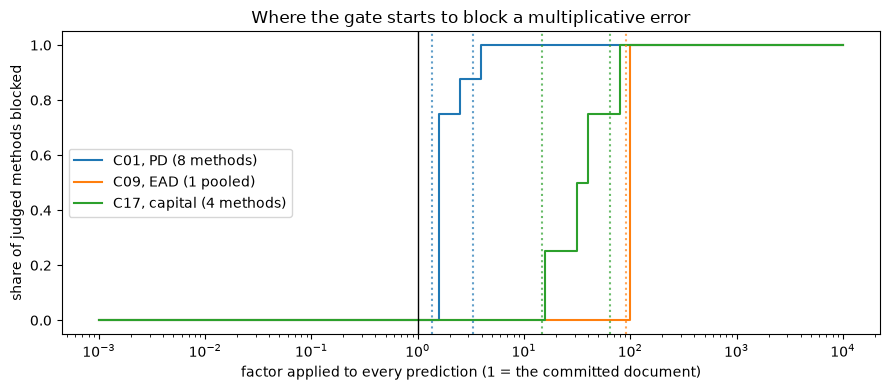

In [23]:
# Draw the share blocked against the factor, with the stated thresholds of the table above as dotted vertical lines
fig, ax = plt.subplots(figsize=(9, 4))
colours = {"C01": "tab:blue", "C09": "tab:orange", "C17": "tab:green"}
names = {"C01": "C01, PD (8 methods)", "C09": "C09, EAD (1 pooled)", "C17": "C17, capital (4 methods)"}
for case in subjects:
    ax.step(factors, share[case], where="post", color=colours[case], label=names[case])
for case, method in probes:
    ax.axvline(stated_threshold(case, method), color=colours[case], linestyle=":", alpha=0.7)
ax.axvline(1.0, color="black", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("factor applied to every prediction (1 = the committed document)")
ax.set_ylabel("share of judged methods blocked")
ax.set_title("Where the gate starts to block a multiplicative error")
ax.legend(loc="center left")
fig.tight_layout()
plt.show()

Each curve is a staircase: zero up to its first threshold and then one step per method until all are blocked, at the dotted lines of the thresholds. The German twin (blue) rises first, in steps that group the thresholds of its eight methods, which lie between 1.35 and 3.33, because its blocking is the domain rule; C17 (green) rises between 14.8 and 64.5, one step per method; and C09 (orange) is a single step at 90.3 because its pair pools the eight methods. Everything to the left of the black line at 1 is flat at zero. The figure shows that a PD written in percent (a factor of 100) is blocked for every method, a capital multiplied by 1,000 is blocked for all four, and a PD multiplied by 1.3 is not blocked. It does not show errors that are not a factor, such as a shift or a sign flip, which the plants of step 7 covered.

The sweep shows two blind spots at once, and each has its own cell.

**An error downward.** A capital in thousands of euros is the capital divided by 1,000, not multiplied. Whether the gate sees a division depends on whether the widened range reaches zero. For a positive observable the lower end of $W$ is $t_{\min} - r\,s$, which is negative as soon as the span exceeds the smallest target, and then every positive prediction, however small, is inside. The next cell gives the same function two targets: one of four values far from zero and one that starts near zero.

In [24]:
# Why nothing is blocked below 1: the widened range reaches zero for a positive observable; give a target away from
# zero
def largest_blocking_factor(target, prediction, factors):
    for k in factors:
        if toy_verdict(toy_pair("series", "EUR"), [p * k for p in prediction], target).violations:
            return k
    return None


far = [100.0, 104.0, 108.0, 112.0]
near_zero = [1.0, 40.0, 80.0, 120.0]
down = [0.9, 0.5, 0.1, 0.01, 0.001, 0.0001]
print(
    "target far from zero:",
    widened_range("series", far),
    "| largest factor below 1 that blocks:",
    largest_blocking_factor(far, far, down),
)
print(
    "target that reaches near zero:",
    widened_range("series", near_zero),
    "|",
    largest_blocking_factor(near_zero, near_zero, down),
)
print("committed C09 document at a factor of 1/1000, methods blocked:", len(blocked_methods("C09", 1e-3)))

target far from zero: [88.0, 124.0] | largest factor below 1 that blocks: 0.5
target that reaches near zero: [-118.0, 239.0] | None
committed C09 document at a factor of 1/1000, methods blocked: 0


For a target of 100 to 112 the widened range is $[88, 124]$ and the gate blocks a prediction divided by 2 (a factor of 0.5): all the scaled predictions fall below 88. For a target that starts at 1 and reaches 120 the range is $[-118, 239]$ and no factor between 0.9 and 0.0001 is blocked. The committed documents are the second case: the C09 backtest at a factor of 1/1,000 blocks 0 of 1 pairs. A capital or an exposure that spans a large part of its own scale is therefore invisible when it is too small by any factor, which is the commonest way a thousand-for-one slip appears. The table shows the rule at work on synthetic targets. It does not say what to do about it; the answer, in the own-data section, is a unit declared in the input and a check that is about units and not ranges.

**An error inside the tolerated range.** The gate blocks only when every nonzero prediction is outside the range. The next cell multiplies every capital of C17 by factors from 1 to 100 and counts the methods blocked.

In [25]:
# An error inside the tolerated range is invisible: a method that multiplies its capital by 10 is judged as the one
# that does not
document = read_json("data/derived/C17/xi-0-8.json")
rows = {}
for k in (1.0, 1.5, 2.0, 4.0, 10.0, 20.0, 100.0):
    result = gate.check_document("C17", "xi-0-8.json", scale(deepcopy(document), "C17", k), spec)
    rows[k] = len({v["method"] for v in result.violations})
pd.Series(rows, name="methods blocked").rename_axis("factor on every capital").to_frame().T

factor on every capital,1.0,1.5,2.0,4.0,10.0,20.0,100.0
methods blocked,0,0,0,0,0,1,4


A method that multiplies its capital by 10 is judged exactly as the one that does not: 0 methods are blocked at factors 1, 1.5, 2, 4 and 10, one at 20 and all four at 100. This is the design, not a defect: the rule forbids an accuracy gate, because the moment the gate starts failing inaccurate but honest predictions it has become an accuracy gate and will be silenced. A capital that is ten times the truth in euros is a bad estimate, and the document reports it as a bad estimate in its own `ratio_to_truth` field. The table shows the tolerance in numbers. It does not decide whether ten times is acceptable, which is not a question of units.

**An exact zero.** Zero is the same number in every unit, so a prediction of exactly 0 gives no evidence about the unit. The stage therefore judges the nonzero predictions only, and an all-zero answer is not blocked. The next cell sets every predicted exposure of C09 to 0 and then plants the factor of 1,000 and overwrites ten of the 56 with zeros.

In [26]:
# An exact zero carries no evidence of scale: an all-zero answer is advisory, and a zero beside a wrong-unit value
# hides nothing
document = read_json("data/derived/C09/level-0.json")
all_zero = scale(deepcopy(document), "C09", 0)
mixed = scale(deepcopy(document), "C09", 1000)
for row in ead_rows(mixed)[:10]:
    row["predicted_ead"] = 0.0
variants = [("every prediction is 0", all_zero), ("10 zeros beside 46 values x 1,000", mixed)]
rows = []
for label, variant in variants:
    result = gate.check_document("C09", "level-0.json", variant, spec)
    classes = ", ".join(sorted({v["class"] for v in result.advisories})) or "-"
    rows.append({"variant": label, "blocking": len(result.violations), "advisory classes": classes})
pd.DataFrame(rows)

,variant,blocking,advisory classes
0,every prediction is 0,0,degenerate_constant_prediction
1,"10 zeros beside 46 values x 1,000",1,-


An answer that is zero everywhere is not blocked: it passes with the advisory `degenerate_constant_prediction`, since a constant over a target that varies is recorded and never refused. And the ten zeros beside 46 values multiplied by 1,000 do not hide anything: the nonzero predictions are all outside the range, so the pair is blocked once. A zero is not evidence for the unit, and it is not evidence against it either. The table shows both outcomes. It does not show that a method which predicts 0 for an observable that has a scale is a method that predicts nothing, which the advisory says in words and the gate leaves to the reader.

**A pair bounded only by its domain.** A bound pair is compared with no target, so the only thing the gate can say about it is whether it leaves its domain. A scaled central tendency of a low-default portfolio is a PD below 0.01 everywhere, and a PD below 0.01 written in percent is still below 1. The next cell takes C05's simulated portfolio and multiplies the central tendency by 1, 100, 500 and 1,000.

In [27]:
# A pair bounded only by its declared domain: a central tendency below 0.01 written in percent is still a valid
# probability
document = read_json("data/derived/C05/ldp-sim-1.json")
central = [v for row in document["outputs"]["bounds"]["scaled_central_tendency"] for v in row["pd"]]
print("largest value of the scaled central tendency:", round(max(central), 5))
print("factor at which it leaves the domain [0, 1]:", round(1 / max(central), 1))
rows = []
for k in (1, 100, 500, 1000):
    planted = deepcopy(document)
    for row in planted["outputs"]["bounds"]["scaled_central_tendency"]:
        row["pd"] = [v * k for v in row["pd"]]
    blocked = len(gate.check_document("C05", "ldp-sim-1.json", planted, spec).violations)
    rows.append({"factor": k, "largest value": round(max(central) * k, 3), "blocking": blocked})
pd.DataFrame(rows)

largest value of the scaled central tendency: 0.00196
factor at which it leaves the domain [0, 1]: 509.1


,factor,largest value,blocking
0,1,0.002,0
1,100,0.196,0
2,500,0.982,0
3,1000,1.964,1


The largest central-tendency PD of the document is 0.00196, so the factor that leaves $[0, 1]$ is 509.1. Factors of 1, 100 and 500 pass, with a largest value of 0.002, 0.196 and 0.982, and only 1,000 is blocked, at 1.964. A PD written in percent, which is the factor of 100, is a perfectly valid probability of 0.196 here and no rule about units can see it. The feature's design records the same limit for this pair. The table shows the factor at which a bound starts to block. It does not show what a reader would do to make such a pair safer: declare a target for it, which the specification cannot do when no truth exists.

**A missing prediction, and a path that finds nothing.** A null prediction is a missing value, a method that has no value there and says so, so it is counted and never refused. A path that resolves to nothing is a different thing, a specification that no longer matches its document, and it is an error. The next cell plants five nulls, all nulls, and a document with the whole block of the backtest deleted.

In [28]:
# A missing prediction is advisory, and a path that finds nothing is an error: the gate never passes what it cannot
# read
document = read_json("data/derived/C09/level-0.json")
some_null, all_null, renamed = deepcopy(document), deepcopy(document), deepcopy(document)
for row in ead_rows(some_null)[:5]:
    row["predicted_ead"] = None
for row in ead_rows(all_null):
    row["predicted_ead"] = None
del renamed["outputs"]["ead_backtest"]
rows = []
for label, variant in [("5 predictions null", some_null), ("every prediction null", all_null)]:
    result = gate.check_document("C09", "level-0.json", variant, spec)
    rows.append(
        {"variant": label, "blocking": len(result.violations), "what it says": result.advisories[0]["detail"][:80]}
    )
try:
    gate.check_document("C09", "level-0.json", renamed, spec)
except gate.UnitGateError as refusal:
    rows.append(
        {"variant": "the backtest block is missing", "blocking": "UnitGateError", "what it says": str(refusal)[:80]}
    )
pd.DataFrame(rows)

,variant,blocking,what it says
0,5 predictions null,0,c09-ead-backtest: 5 of 56 predictions are null...
1,every prediction null,0,c09-ead-backtest: 56 of 56 predictions are nul...
2,the backtest block is missing,UnitGateError,pair 'c09-ead-backtest': the prediction path '...


Five nulls give the advisory `5 of 56 predictions are null (missing, not checked)`, and 56 nulls give `56 of 56`: neither blocks, and a document whose predictions are all null passes the gate with no unit judged at all. The deleted block raises `UnitGateError` with the pair, the role (prediction), the path and the document, so a pair that finds nothing is never a pass. Two things follow. A pass of the gate is a pass over the predictions it could read, and the advisory count is part of the verdict: a reader who looks only at the number of blocking violations misses a document with nothing to judge. And the gate cannot tell a method that legitimately has no value from one whose value was lost; the document says which, in its own null reasons. The table lists the three cases. The next section applies the gate to a file that is not in the repository.

### Using it on your own data

The gate reads a document (a dictionary read from JSON) and a pair that says where its prediction and its target sit. To use it on a file of your own you need three things: the document in the shape of the pair's paths, the pair declared in the specification with its kind, unit and, for a bounded observable, domain and reason, and a case id for the entry. The next cell builds, in the notebook, a small frame that stands for your file: 40 loans with a realised exposure in US dollars and one forecast of it in three versions, in dollars, in cents (a factor of 100) and in thousands of dollars (divided by 1,000). It declares the pair with the kind `series`, the unit `USD` and the domain $[0, \infty)$, and validates the specification before any document is read.

In [29]:
# A file of your own, built here as a small frame: one forecast of exposure in USD, in cents and in thousands,
# beside outcomes in USD
rng = np.random.default_rng(7)
my_loans = pd.DataFrame({"loan": range(1, 41), "realised_usd": rng.lognormal(mean=11.5, sigma=0.5, size=40).round(0)})
my_loans["forecast_usd"] = (my_loans["realised_usd"] * rng.normal(1.0, 0.15, size=40)).round(0)
my_loans["forecast_cents"] = my_loans["forecast_usd"] * 100
my_loans["forecast_kusd"] = (my_loans["forecast_usd"] / 1000).round(2)
note = "An exposure is a non-negative amount by definition."
my_pair = {
    "id": "my-ead",
    "file": "my-loans.json",
    "prediction": "rows[].forecast",
    "target": "rows[].realised",
    "kind": "series",
    "unit": "USD",
    "domain": [0, None],
    "domain_reason": note,
}
my_spec = {"C99": {"pairs": [my_pair]}}
gate.validate_spec(my_spec)
print("loans:", len(my_loans), "| median realised:", f"{my_loans['realised_usd'].median():,.0f} USD")
print(
    "median forecast in USD, cents and thousands of USD:",
    my_loans[["forecast_usd", "forecast_cents", "forecast_kusd"]].median().round(0).tolist(),
)

loans: 40 | median realised: 82,356 USD
median forecast in USD, cents and thousands of USD: [86824.0, 8682400.0, 87.0]


The frame has 40 loans with a median realised exposure of 82,356 US dollars, and the medians of the three forecast columns are 86,824, 8,682,400 and 87: the same forecast in three units. The specification validated without an error, which is the first thing to read: a pair that is malformed stops here. The next cell builds the document the pair reads, `{"rows": [{"forecast": ..., "realised": ...}]}` (the paths of the pair are `rows[].forecast` and `rows[].realised`), and judges each column.

In [30]:
# Build the document the pair reads from the frame, then run the gate with the column in USD, in cents and in
# thousands
def loans_document(frame, forecast_column):
    return {
        "rows": [
            {"forecast": float(f), "realised": float(r)} for f, r in zip(frame[forecast_column], frame["realised_usd"])
        ]
    }


rows = []
for column in ("forecast_usd", "forecast_cents", "forecast_kusd"):
    result = gate.check_document("C99", "my-loans.json", loans_document(my_loans, column), my_spec)
    classes = ", ".join(sorted({v["class"] for v in result.violations})) or "-"
    rows.append(
        {
            "forecast column": column,
            "pairs checked": result.pairs_checked,
            "blocking": len(result.violations),
            "class": classes,
        }
    )
pd.DataFrame(rows)

,forecast column,pairs checked,blocking,class
0,forecast_usd,1,0,-
1,forecast_cents,1,1,prediction_outside_observable
2,forecast_kusd,1,0,-


The forecast in dollars passes with one pair checked and no violation. The forecast in cents is blocked by `prediction_outside_observable`: all 40 values lie far above the widened range. The forecast in thousands passes, exactly as the downward section predicted: the realised exposures range from tens of thousands to a few hundred thousand dollars, their widened range starts below zero, and a forecast of 87 is inside it. This is the most useful lesson for your own data. The gate caught the factor of 100 and missed the factor of 1/1,000 on the same file, so a pass says the forecast is not too large by a wide factor, never that it is in the right unit. What to check in the output of a run on your own data is therefore the count of pairs checked (zero means the glob matched no document), the blocking violations with their class and message, and the advisories; and what to add by hand is a statement of the unit in the file itself, which the gate does not read. The last cell shows what the validator says about the three mistakes of writing a pair.

In [31]:
# A malformed pair is refused before any document is read: three mistakes the validator names
bad = {
    "a domain without its reason": {k: v for k, v in my_pair.items() if k != "domain_reason"},
    "a series without its target": {k: v for k, v in my_pair.items() if k != "target"},
    "a field the gate does not know": {**my_pair, "tolerance": 0.1},
}
rows = []
for label, pair in bad.items():
    try:
        gate.validate_pair(pair)
        said = "accepted"
    except gate.UnitGateError as refusal:
        said = str(refusal)
    rows.append({"mistake": label, "the validator says": said})
pd.DataFrame(rows)

,mistake,the validator says
0,a domain without its reason,pair 'my-ead': a 'domain' needs its 'domain_re...
1,a series without its target,pair 'my-ead': kind 'series' needs its 'target...
2,a field the gate does not know,pair 'my-ead': unknown field(s) ['tolerance']


A domain without its reason, a series without its target and a field the gate does not know are each refused with a sentence that names the pair and the rule, before any document is read. The refusals are the specification's own checks: a domain needs its one-sentence reason, a series needs its target path, and no field outside the list of the stage is accepted. They are the reason to write a pair in the specification and not in code. To make the check part of your own run, put the pair in the specification of a copy of the repository tree (the script takes a repository root and reads `data-pipeline/config/unit_pairs.json` and `data/derived/<case>/` inside it) under a case id and run the shipped check, `python scripts/check_units.py <root>`, which also reports a glob that matches no file and a case folder with no entry.

## Results

**Answer:** A number that is right in its own unit and wrong in the unit of the question is seen by the gate when it leaves a range as wide as the target's own span on each side, or leaves the declared domain of a bounded observable. On the committed documents the gate judged 8 pairs of 4 cases and blocked none, and each planted error was blocked: a PD in percent 13 times, an exposure multiplied by 1,000 once, and the sign flips of an exposure and of a capital. The thresholds are measured, not assumed: a PD starts to block at a factor of 1.350 (the domain rule), the pooled exposure of C09 at 90.331 and the SLA capital of C17 at 14.760, equal to the equations $d_{\mathrm{hi}}/p_{\max}$ and $w_{\mathrm{hi}}/p_{\min}$ to a relative gap of $10^{-11}$. What it lets through is an error inside the range (a capital multiplied by 10), an error downward (0 methods blocked at a factor of 1/1,000, a forecast in thousands that passes), an exact zero, a bound that is only a domain (a PD in percent of 0.196) and a missing prediction.

- **Failure.** A PD of 22, a capital of 163,483,000 against 163,483 and a constant of 1.00 against 433 to 484 are each blocked; the engine's AUC is 0.7566 for the PD as baked, in percent and divided by 10, and its calibration tests refuse the percent and turn the divided PD red.
- **Rule.** Four kinds of target with their widened ranges: $[-1, 2]$ for 80 binary PDs, $[-207{,}327{,}763,\ 425{,}928{,}805]$ for the 56 exposures, $[0, 1.7]$ for a share of 0.85 and $[0, 3.27\cdot 10^{8}]$ for the C17 capital, of which 68 of 80 quantiles are inside.
- **Specification.** 21 cases, 53 pairs, 21 domains on the estimating kinds and 14 on bounds, 9 zero scales.
- **Where it breaks.** Not blocked: a factor of 10 on a capital, any factor below 1 on the committed documents, a zero, a central tendency in percent and a null.
- **Your own data.** A forecast in cents is blocked and the same forecast in thousands passes: add the unit to the file and read the advisories.

What this notebook does not do: it does not judge accuracy, it does not run the check inside the bake, which is planned for the next release, and it plants only errors of scale and sign.

## Summary

- A gate that asks whether the pipeline ran cannot see an answer in the wrong unit: the engine's AUC is 0.7566 for a PD as baked, in percent and divided by 10, and only the tests that read the probability refuse the percent.
- The stage `unit_gate` widens a target by its own span on each side (a series), by the label's domain (a 0/1 outcome, $[-1, 2]$), by its own absolute value (one known truth) or not at all (a bound), blocks a pair whose nonzero predictions all lie outside, or any of whose predictions leaves a declared domain or is not finite, and only records a null or a constant prediction.
- The specification holds 21 cases and 53 pairs as data, validated before use; the gate judged 8 pairs on four committed documents and blocked none, and blocked every plant: a percent 13 times, a factor of 1,000, two sign flips.
- A multiplicative error starts to block at a threshold the rule fixes, $w_{\mathrm{hi}}/p_{\min}$ or $d_{\mathrm{hi}}/p_{\max}$, measured here from 1.350 to 90.331, and the measured values equal the equations to a relative gap of $10^{-11}$.
- It lets through an error inside the range, any error downward on an observable whose range reaches zero, an exact zero, a bound inside its domain and a null; a pass is never a statement that the unit is right.
- At release 1.01.000 the gate judges the committed documents, in continuous integration and before a deployment; the check inside the bake is planned for the next release.

**What to try next.** Plant a sign flip on the C16 share and an exposure divided by 100 on C09 and read both verdicts; then declare a pair for a file of your own with a `domain` and run `scripts/check_units.py` on a copy of the specification. Continue with notebook 07, which compares the methods of the product on one protocol.

## References

- Mavin, A., Wilkinson, P., Harwood, A. and Novak, M. (2009), Easy Approach to Requirements Syntax (EARS), the form in which the requirements of the unit gate are written, RE'09. https://doi.org/10.1109/RE.2009.9
- Basel Committee, Basel Framework, CRE32, the IRB approach (PD as an input and its floor), as the design document cites it. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Basel Committee (2023), Report on the 2023 banking turmoil, the source of the observed share of deposits of case C16. https://www.bis.org/bcbs/publ/d555.htm
- Basel Committee (2016), Standardised Measurement Approach for operational risk, consultative document, the reference of the capital of case C17. https://www.bis.org/bcbs/publ/d355.htm
- Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- riskvalidation 1.1.0, the engine release the notebooks pin. https://pypi.org/project/riskvalidation/1.1.0/
- This repository: `data-pipeline/pipeline/stages/unit_gate.py`, `data-pipeline/config/unit_pairs.json`, `scripts/check_units.py`, `docs/design/features/units/` and `tests/test_unit_gate.py`.